In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

In [3]:
df = pd.read_csv('superstore_sales.csv')
df['order_date'] = pd.to_datetime(df['order_date'], format='%m/%d/%Y')
df.head()

,row_id,order_id,order_date,order_priority,order_quantity,sales,discount,ship_mode,profit,unit_price,...,customer_name,province,region,customer_segment,product_category,product_sub_category,product_name,product_container,product_base_margin,ship_date
0,1,3,2010-10-13,Low,6,261.5400,0.04,Regular Air,-213.25,38.94,...,Muhammed MacIntyre,Nunavut,Nunavut,Small Business,Office Supplies,Storage & Organization,"Eldon Base for stackable storage shelf, platinum",Large Box,0.80,10/20/2010
1,49,293,2012-10-01,High,49,10123.0200,0.07,Delivery Truck,457.81,208.16,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,"1.7 Cubic Foot Compact ""Cube"" Office Refrigera...",Jumbo Drum,0.58,10/2/2012
2,50,293,2012-10-01,High,27,244.5700,0.01,Regular Air,46.71,8.69,...,Barry French,Nunavut,Nunavut,Consumer,Office Supplies,Binders and Binder Accessories,"Cardinal Slant-D¨ Ring Binder, Heavy Gauge Vinyl",Small Box,0.39,10/3/2012
3,80,483,2011-07-10,High,30,4965.7595,0.08,Regular Air,1198.97,195.99,...,Clay Rozendal,Nunavut,Nunavut,Corporate,Technology,Telephones and Communication,R380,Small Box,0.58,7/12/2011
4,85,515,2010-08-28,Not Specified,19,394.2700,0.08,Regular Air,30.94,21.78,...,Carlos Soltero,Nunavut,Nunavut,Consumer,Office Supplies,Appliances,Holmes HEPA Air Purifier,Medium Box,0.50,8/30/2010


In [4]:
df.shape

(8399, 21)

In [5]:
df.dtypes

row_id                           int64
order_id                         int64
order_date              datetime64[us]
order_priority                     str
order_quantity                   int64
sales                          float64
discount                       float64
ship_mode                          str
profit                         float64
unit_price                     float64
shipping_cost                  float64
customer_name                      str
province                           str
region                             str
customer_segment                   str
product_category                   str
product_sub_category               str
product_name                       str
product_container                  str
product_base_margin            float64
ship_date                          str
dtype: object

In [6]:
df.isnull().sum()

row_id                   0
order_id                 0
order_date               0
order_priority           0
order_quantity           0
sales                    0
discount                 0
ship_mode                0
profit                   0
unit_price               0
shipping_cost            0
customer_name            0
province                 0
region                   0
customer_segment         0
product_category         0
product_sub_category     0
product_name             0
product_container        0
product_base_margin     63
ship_date                0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(0)

### Summary statistics table

In [8]:
num_cols = ['order_quantity', 'sales', 'discount', 'profit',
            'unit_price', 'shipping_cost', 'product_base_margin']

summary = df[num_cols].describe().T.round(2)
summary

,count,mean,std,min,25%,50%,75%,max
order_quantity,8399.0,25.57,14.48,1.00,13.00,26.00,38.00,50.00
sales,8399.0,1775.88,3585.05,2.24,143.20,449.42,1709.32,89061.05
discount,8399.0,0.05,0.03,0.00,0.02,0.05,0.08,0.25
profit,8399.0,181.18,1196.65,-14140.70,-83.32,-1.50,162.75,27220.69
unit_price,8399.0,89.35,290.35,0.99,6.48,20.99,85.99,6783.02
shipping_cost,8399.0,12.84,17.26,0.49,3.30,6.07,13.99,164.73
product_base_margin,8336.0,0.51,0.14,0.35,0.38,0.52,0.59,0.85


### Distributions of all numeric columns

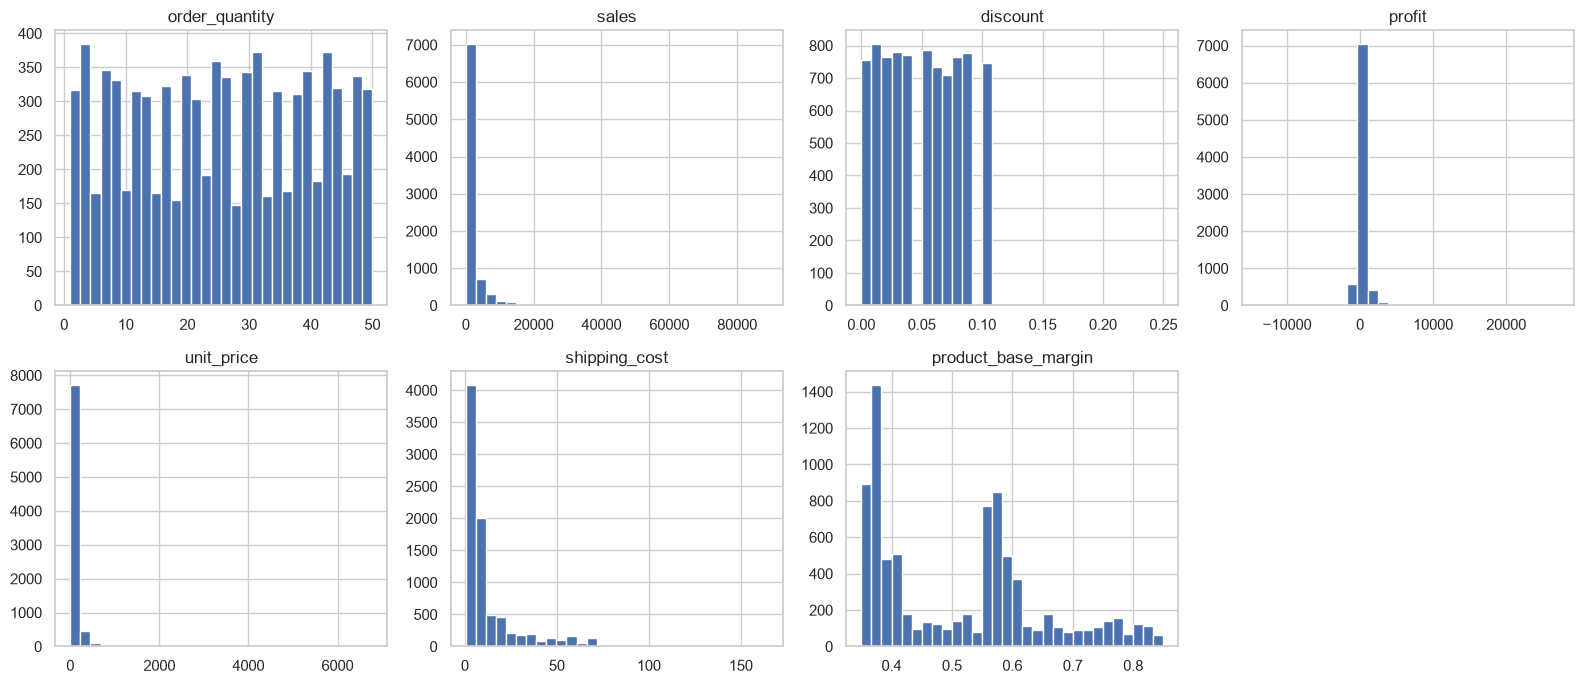

In [9]:
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
axes = axes.flatten()

for i, col in enumerate(num_cols):
    axes[i].hist(df[col].dropna(), bins=30, edgecolor='white')
    axes[i].set_title(col)

axes[7].axis('off')
plt.tight_layout()
plt.savefig('distributions.png', dpi=150)
plt.show()

### Correlation heatmap

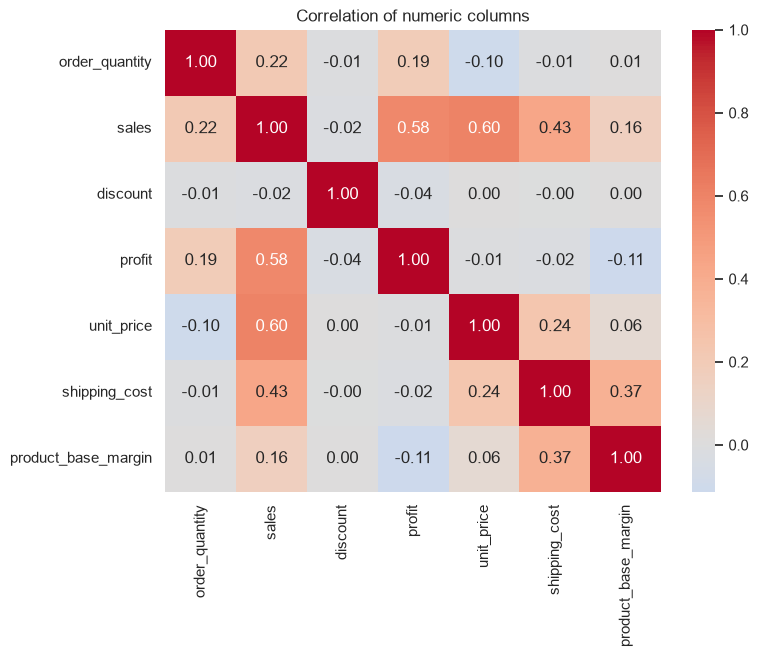

In [10]:
plt.figure(figsize=(8, 6))
sns.heatmap(df[num_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation of numeric columns')
plt.savefig('heatmap.png', dpi=150, bbox_inches='tight')
plt.show()

# Business Insights

### Insight 1: Technology earns the most profit, Furniture has the weakest margin

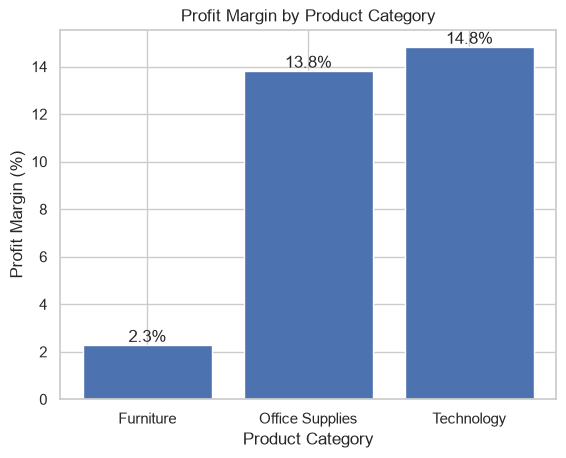

In [11]:
cat = df.groupby('product_category')[['sales', 'profit']].sum()
cat['margin_pct'] = cat['profit'] / cat['sales'] * 100

bars = plt.bar(cat.index, cat['margin_pct'])
plt.bar_label(bars, fmt='%.1f%%')
plt.title('Profit Margin by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Profit Margin (%)')
plt.savefig('insight1.png', dpi=150)
plt.show()

### Insight 2: Tables and Bookcases lose money

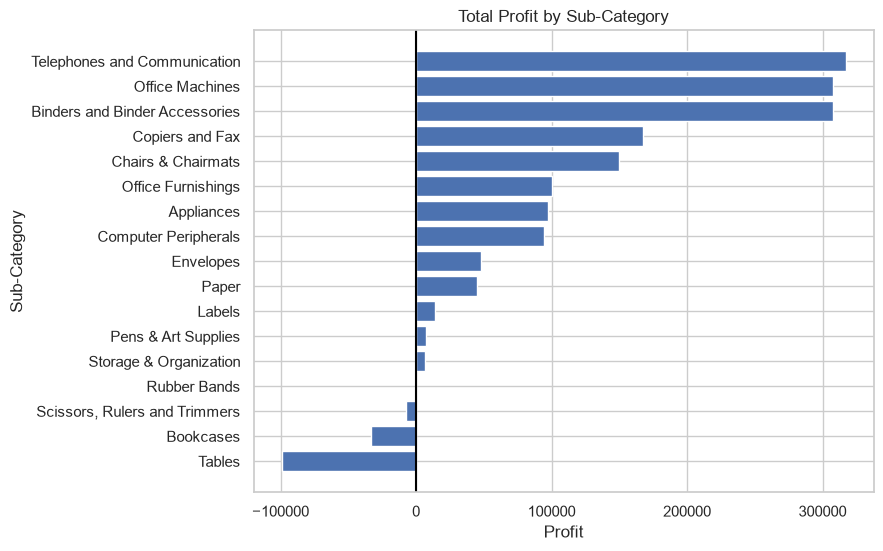

In [12]:
sub = df.groupby('product_sub_category')['profit'].sum().sort_values()

plt.figure(figsize=(8, 6))
plt.barh(sub.index, sub.values)
plt.axvline(0, color='black')
plt.title('Total Profit by Sub-Category')
plt.xlabel('Profit')
plt.ylabel('Sub-Category')
plt.savefig('insight2.png', dpi=150, bbox_inches='tight')
plt.show()

### Insight 3: Delivery Truck has high sales but low profit

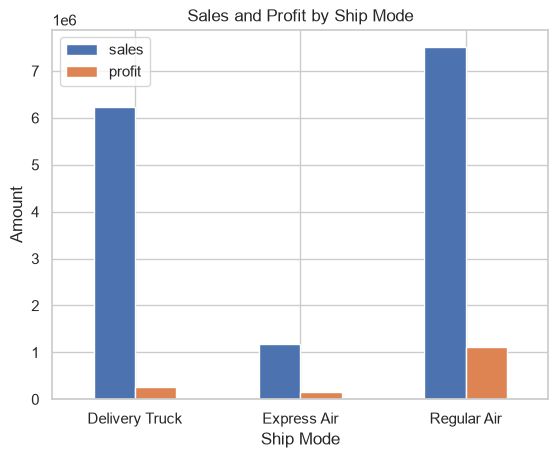

In [13]:
ship = df.groupby('ship_mode')[['sales', 'profit']].sum()

ship.plot(kind='bar')
plt.title('Sales and Profit by Ship Mode')
plt.xlabel('Ship Mode')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.savefig('insight3.png', dpi=150)
plt.show()

### Insight 4: Higher discounts go with lower profit

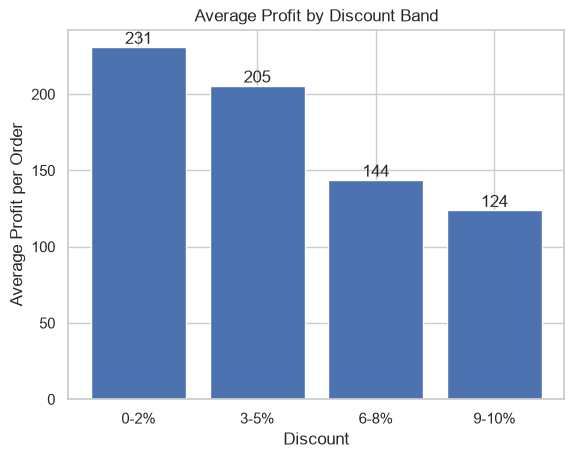

In [14]:
df['discount_band'] = pd.cut(df['discount'], bins=[-0.01, 0.02, 0.05, 0.08, 0.11],
                             labels=['0-2%', '3-5%', '6-8%', '9-10%'])
disc = df.groupby('discount_band', observed=True)['profit'].mean()

bars = plt.bar(disc.index.astype(str), disc.values)
plt.bar_label(bars, fmt='%.0f')
plt.title('Average Profit by Discount Band')
plt.xlabel('Discount')
plt.ylabel('Average Profit per Order')
plt.savefig('insight4.png', dpi=150)
plt.show()

### Insight 5: Sales dropped after 2009

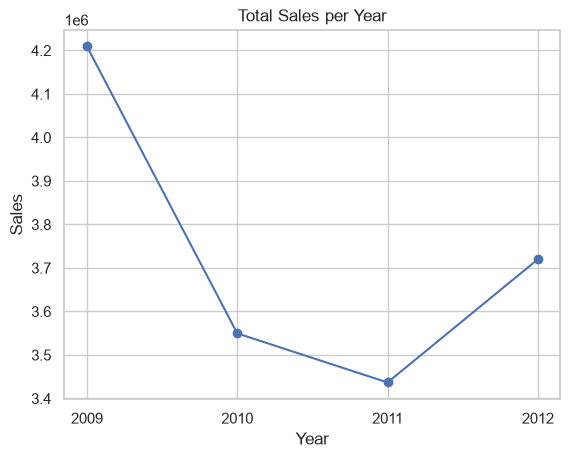

In [15]:
yearly = df.groupby(df['order_date'].dt.year)['sales'].sum()

plt.plot(yearly.index, yearly.values, marker='o')
plt.xticks(yearly.index)
plt.title('Total Sales per Year')
plt.xlabel('Year')
plt.ylabel('Sales')
plt.savefig('insight5.png', dpi=150)
plt.show()